# Análisis exploratorio: NIH ChestX-ray14 y derrame pleural (*Effusion*)

Este notebook reúne el análisis de datos que justifica cómo se armaron train, validación y test. Cada sección termina con la **decisión** que se tomó a partir de lo que muestra.

| Sección | Qué mira | Necesita |
|---|---|---|
| 1 a 5 | Metadatos de las 112.120 radiografías: pacientes, hallazgos, vistas y negativas | `data/raw/nih/Data_Entry_2017_v2020.csv` y `test_list.txt` |
| 6 a 8 | Los conjuntos que generó la preparación y las imágenes de train | `data/processed/nih_effusion_pa_40_60_v1/` (`rx-preparar --config configs/nih.json`) |
| 9 | La población del test oficial, analizada **después** de evaluar el modelo B | Los dos anteriores |
| 10 | Resumen de decisiones | - |

Las decisiones sobre las imágenes (secciones 7 y 8) se toman mirando **solo train**. De validación y test solo se cuentan cantidades para verificar que los conjuntos estén bien armados.

Para ejecutarlo: `python -m pip install -e ".[notebooks]"` y después *Run All*. Tarda menos de un minuto. Con el dataset descargado como explica [`docs/PREPARAR_DATOS.md`](../docs/PREPARAR_DATOS.md), reproduce todos los números.

In [1]:
import csv
import json
import math
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

# Raíz del repositorio, aunque el notebook se abra desde notebooks/.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'pyproject.toml').exists())
if str(PROJECT_ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT / 'src'))

from rx_torax.data.splits import FOLLOW_UP_BINS, follow_up_bin
from rx_torax.evaluation.metrics import roc_auc
from rx_torax.preprocessing.images import read_image, transform

NIH = PROJECT_ROOT / 'data' / 'raw' / 'nih'
PREPARADOS = PROJECT_ROOT / 'data' / 'processed' / 'nih_effusion_pa_40_60_v1'
TARGET = 'Effusion'
SEED = 42
COLOR = {0: '#7b8ca4', 1: '#c8563f'}  # sin / con Effusion, como en las figuras de docs/
plt.rcParams.update({'figure.dpi': 90, 'axes.spines.top': False, 'axes.spines.right': False})


def requiere(path, como):
    if not path.exists():
        raise FileNotFoundError(f'Falta {path.relative_to(PROJECT_ROOT)}. {como}')


def n(valor):
    """Miles con punto, como en el resto de la documentación."""
    return f'{int(valor):,}'.replace(',', '.')


def dec(valor, decimales=1):
    return f'{valor:.{decimales}f}'.replace('.', ',')


def pct(parte, total, decimales=1):
    return dec(100 * parte / total, decimales) + '%'


class Tabla:
    """Tabla HTML en el notebook y texto alineado en consola, sin depender de pandas."""

    def __init__(self, encabezado, filas):
        self.encabezado = [str(c) for c in encabezado]
        self.filas = [[str(c) for c in fila] for fila in filas]

    def _repr_html_(self):
        cabeza = ''.join(f'<th>{c}</th>' for c in self.encabezado)
        cuerpo = ''.join('<tr>' + ''.join(f'<td>{c}</td>' for c in fila) + '</tr>' for fila in self.filas)
        return f'<table><thead><tr>{cabeza}</tr></thead><tbody>{cuerpo}</tbody></table>'

    def __repr__(self):
        anchos = [max(map(len, columna)) for columna in zip(self.encabezado, *self.filas)]
        linea = lambda celdas: '  '.join(c.ljust(a) for c, a in zip(celdas, anchos))
        return '\n'.join([linea(self.encabezado), linea(['-' * a for a in anchos]), *map(linea, self.filas)])


print('Raíz del proyecto encontrada; datos en', NIH.relative_to(PROJECT_ROOT))

Raíz del proyecto encontrada; datos en data/raw/nih


## 1. El dataset: radiografías y pacientes

NIH ChestX-ray14 trae un CSV con una fila por radiografía: nombre del archivo, hallazgos, paciente, número de estudio previo (`Follow-up #`), edad, sexo, vista y tamaño original. El test oficial es la lista `test_list.txt`.

In [2]:
requiere(NIH / 'Data_Entry_2017_v2020.csv', 'Descargar NIH ChestX-ray14 como explica docs/PREPARAR_DATOS.md.')
with open(NIH / 'Data_Entry_2017_v2020.csv', newline='', encoding='utf-8') as stream:
    filas = list(csv.DictReader(stream))
columnas = list(filas[0])
test_oficial = set((NIH / 'test_list.txt').read_text().split())

por_nombre = {}
for r in filas:
    r['hallazgos'] = r['Finding Labels'].split('|')
    r['y'] = int(TARGET in r['hallazgos'])
    r['lista'] = 'test' if r['Image Index'] in test_oficial else 'train_val'
    r['previos'] = int(r['Follow-up #'])
    r['edad'] = int(r['Patient Age'])
    # La cabecera dice "OriginalImage[Width,Height]": la coma de adentro la parte en dos columnas.
    r['ancho'], r['alto'] = int(r['OriginalImage[Width']), int(r['Height]'])
    por_nombre[r['Image Index']] = r

pacientes = Counter(r['Patient ID'] for r in filas)
print(f'{n(len(filas))} radiografías de {n(len(pacientes))} pacientes')
print(f'Test oficial: {n(len(test_oficial))} radiografías; train_val: {n(len(filas) - len(test_oficial))}')
print('Columnas del CSV:', ', '.join(columnas))

112.120 radiografías de 30.805 pacientes
Test oficial: 25.596 radiografías; train_val: 86.524
Columnas del CSV: Image Index, Finding Labels, Follow-up #, Patient ID, Patient Age, Patient Sex, View Position, OriginalImage[Width, Height], OriginalImagePixelSpacing[x, y]


Pacientes con más de una radiografía: 43,2%
Radiografías que pertenecen a esos pacientes: 84,4%
Radiografías por paciente: mediana 1, máximo 184


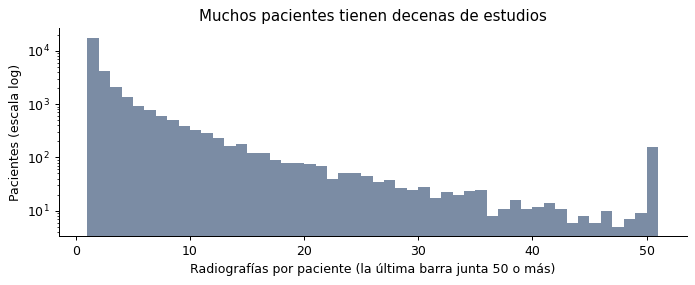

In [3]:
por_paciente = np.array(list(pacientes.values()))
varias = por_paciente > 1
print(f'Pacientes con más de una radiografía: {pct(varias.sum(), len(por_paciente))}')
print(f'Radiografías que pertenecen a esos pacientes: {pct(por_paciente[varias].sum(), len(filas))}')
print(f'Radiografías por paciente: mediana {np.median(por_paciente):.0f}, máximo {por_paciente.max()}')

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(np.minimum(por_paciente, 50), bins=np.arange(1, 52), color=COLOR[0])
ax.set_yscale('log')
ax.set_xlabel('Radiografías por paciente (la última barra junta 50 o más)')
ax.set_ylabel('Pacientes (escala log)')
ax.set_title('Muchos pacientes tienen decenas de estudios')
plt.show()

In [4]:
anchos = np.array([r['ancho'] for r in filas])
altos = np.array([r['alto'] for r in filas])
print(f'Tamaño original, según el CSV: mediana {np.median(anchos):.0f} × {np.median(altos):.0f} px '
      f'(ancho entre {anchos.min()} y {anchos.max()})')
print('El NIH publicó todas las imágenes achicadas a 1024 × 1024; la sección 6 lo verifica en las que se usan.')

Tamaño original, según el CSV: mediana 2518 × 2544 px (ancho entre 1143 y 3827)
El NIH publicó todas las imágenes achicadas a 1024 × 1024; la sección 6 lo verifica en las que se usan.


**Decisión: separar por paciente.** El 84% de las radiografías es de pacientes con más de un estudio, y las de una misma persona se parecen entre sí. Si un paciente quedara en train y en test, el modelo podría reconocer a la persona en vez del hallazgo y el resultado saldría inflado. Todas las imágenes de un paciente van al mismo conjunto.

### Faltantes, rangos y forma de las variables

Antes de usar el CSV hay que contar los faltantes de cada columna y decidir si se eliminan o se imputan (slides 05, pp. 17 y 20), y revisar que no haya valores imposibles. Después se describe cada variable numérica con medidas de tendencia central, de dispersión y de forma (slides 03, pp. 19-27): si la asimetría pasa de 1 en valor absoluto, la media deja de ser representativa y conviene resumir con mediana e IQR.

Las medidas de forma se calculan sobre las 67.310 radiografías PA, que son las que se usan (sección 3).

In [5]:
edades = np.array([r['edad'] for r in filas])
print(f'Edad: de {edades.min()} a {edades.max()} años ({n((edades == 0).sum())} radiografías de menores de un año)')
print('Sexo:', dict(Counter(r['Patient Sex'] for r in filas)), '| Vista:', dict(Counter(r['View Position'] for r in filas)))
print(f"Estudios previos: de {min(r['previos'] for r in filas)} a {max(r['previos'] for r in filas)}")
faltantes = {c: sum(not (r[c] or '').strip() for r in filas) for c in columnas}
Tabla(['Columna del CSV', 'Faltantes', '% de las filas'], [[c, n(k), pct(k, len(filas))] for c, k in faltantes.items()])

Edad: de 0 a 95 años (14 radiografías de menores de un año)
Sexo: {'M': 63340, 'F': 48780} | Vista: {'PA': 67310, 'AP': 44810}
Estudios previos: de 0 a 183


Columna del CSV,Faltantes,% de las filas
Image Index,0,"0,0%"
Finding Labels,0,"0,0%"
Follow-up #,0,"0,0%"
Patient ID,0,"0,0%"
Patient Age,0,"0,0%"
Patient Sex,0,"0,0%"
View Position,0,"0,0%"
OriginalImage[Width,0,"0,0%"
Height],0,"0,0%"
OriginalImagePixelSpacing[x,0,"0,0%"


In [6]:
def describir(nombre, valores):
    """Como describe() de pandas, más IQR, asimetría y curtosis en exceso (0 = normal), con corrección muestral."""
    x = np.asarray(valores, dtype=float)
    m = len(x)
    q1, mediana, q3 = np.percentile(x, [25, 50, 75])
    z = x - x.mean()
    g1 = (z ** 3).mean() / (z ** 2).mean() ** 1.5
    g2 = (z ** 4).mean() / (z ** 2).mean() ** 2 - 3
    asimetria = g1 * math.sqrt(m * (m - 1)) / (m - 2)
    curtosis = ((m + 1) * g2 + 6) * (m - 1) / ((m - 2) * (m - 3))
    entero = lambda v: n(v) if float(v).is_integer() else dec(v)
    return [nombre, n(m), dec(x.mean(), 2), entero(mediana), dec(x.std(ddof=1), 2),  # desvío muestral, con n - 1
            entero(q1), entero(q3), entero(q3 - q1), f'{x.min():.0f} a {x.max():.0f}', dec(asimetria, 2), dec(curtosis, 2)]


pa = [r for r in filas if r['View Position'] == 'PA']
print('Tipos: edad y estudios previos (Follow-up #), numéricas discretas; sexo y vista, categóricas binarias; '
      'Finding Labels, categórica multietiqueta; Effusion (el target), binaria.')
Tabla(['Variable (solo PA)', 'n', 'Media', 'Mediana', 'Desvío', 'Q1', 'Q3', 'IQR', 'Rango', 'Asimetría', 'Curtosis'],
      [describir('Edad', [r['edad'] for r in pa]),
       describir('Estudios previos (Follow-up #)', [r['previos'] for r in pa]),
       describir('Radiografías PA por paciente', list(Counter(r['Patient ID'] for r in pa).values()))])

Tipos: edad y estudios previos (Follow-up #), numéricas discretas; sexo y vista, categóricas binarias; Finding Labels, categórica multietiqueta; Effusion (el target), binaria.


Variable (solo PA),n,Media,Mediana,Desvío,Q1,Q3,IQR,Rango,Asimetría,Curtosis
Edad,67.310,"47,14",49,"16,18",35,59,24,0 a 95,"-0,28","-0,48"
Estudios previos (Follow-up #),67.310,"4,78",1,"9,23",0,6,6,0 a 128,"4,24","26,50"
Radiografías PA por paciente,28.868,"2,33",1,"3,29",1,2,1,1 a 100,"6,60","84,89"


**Decisiones:**

- **No se imputa ni se elimina nada por faltantes:** las 11 columnas del CSV están completas y no hay valores imposibles. Las edades van de 0 a 95 años (las de 0 son bebés de menos de un año), el sexo es M o F, la vista PA o AP y los estudios previos empiezan en 0.
- **La edad se resume con la media.** Es casi simétrica (asimetría −0,28) y la media (47,1) queda cerca de la mediana (49).
- **Los estudios previos y las radiografías por paciente se resumen con mediana e IQR.** Son muy asimétricos a la derecha (asimetría 4,2 y 6,6) y tienen colas largas (curtosis 26,5 y 84,9): unos pocos pacientes con decenas de estudios tiran la media para arriba (4,8 estudios previos contra una mediana de 1). Por eso las tablas de las secciones 3 y 7 usan la mediana y el porcentaje con 10 o más estudios previos, no la media.

## 2. Hallazgos

Cada radiografía puede tener varias de las 14 etiquetas, o *No Finding*. Las etiquetas salieron de procesar los informes con NLP, no de un radiólogo mirando la imagen.

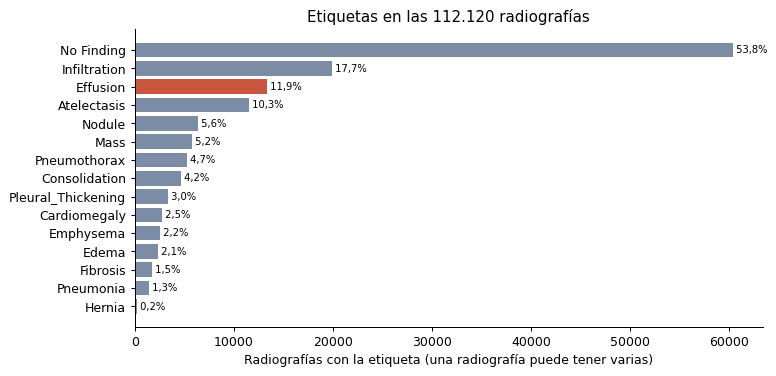

Radiografías con más de un hallazgo: 18,5%


In [7]:
conteo = Counter(h for r in filas for h in r['hallazgos'])
orden = sorted(conteo, key=conteo.get)
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.barh(orden, [conteo[h] for h in orden], color=[COLOR[1] if h == TARGET else COLOR[0] for h in orden])
for i, h in enumerate(orden):
    ax.text(conteo[h], i, ' ' + pct(conteo[h], len(filas)), va='center', fontsize=8)
ax.set_xlabel('Radiografías con la etiqueta (una radiografía puede tener varias)')
ax.set_title(f'Etiquetas en las {n(len(filas))} radiografías')
plt.show()
print(f'Radiografías con más de un hallazgo: {pct(sum(len(r["hallazgos"]) > 1 for r in filas), len(filas))}')

In [8]:
con_derrame = [r for r in filas if r['y']]
solo = sum(len(r['hallazgos']) == 1 for r in con_derrame)
junto = Counter(h for r in con_derrame for h in r['hallazgos'] if h != TARGET)
print(f'{n(len(con_derrame))} radiografías con {TARGET}; en {pct(solo, len(con_derrame))} es el único hallazgo.')
Tabla(['Hallazgo que aparece junto con Effusion', 'Radiografías', '% de las que tienen Effusion'],
      [[h, n(c), pct(c, len(con_derrame))] for h, c in junto.most_common(6)])

13.317 radiografías con Effusion; en 29,7% es el único hallazgo.


Hallazgo que aparece junto con Effusion,Radiografías,% de las que tienen Effusion
Infiltration,4.000,"30,0%"
Atelectasis,3.275,"24,6%"
Consolidation,1.287,"9,7%"
Mass,1.254,"9,4%"
Cardiomegaly,1.063,"8,0%"
Pneumothorax,996,"7,5%"


**Decisión: clasificación binaria, con 1 = la radiografía tiene la etiqueta *Effusion*, sola o con otras.** La mayoría de los derrames viene acompañada de otros hallazgos, así que exigir *Effusion* sola dejaría afuera la mayor parte de los positivos. Un 0 no significa radiografía normal: significa que *Effusion* no está anotada.

### Cuánto desbalance hay

El desbalance se identifica antes de entrenar, con gráficos, frecuencias e índices (slides 05, p. 7; slides 06, p. 25). Con dos clases, la **entropía de Shannon** vale 1 bit cuando están 50% y 50%, y baja cuanto más domina una; el **índice de Gini** (1 − Σp²) vale 0,5 con balance perfecto y se acerca a 0 cuando una clase se queda con casi todo.

In [9]:
def entropia(p):
    return -sum(q * math.log2(q) for q in (p, 1 - p) if q > 0)


def gini(p):
    return 1 - p ** 2 - (1 - p) ** 2


test_pa = [r for r in pa if r['lista'] == 'test']
grupos_balance = [('Todas las PA', len(pa), sum(r['y'] for r in pa) / len(pa)),
                  ('Test oficial, solo PA', len(test_pa), sum(r['y'] for r in test_pa) / len(test_pa)),
                  ('Train, validación y test preparados (objetivo)', None, 0.4),
                  ('Referencia: balance perfecto', None, 0.5)]
Tabla(['Grupo', 'Radiografías', 'Con Effusion', 'Entropía (bits)', 'Gini'],
      [[nombre, n(total) if total else '-', dec(100 * p) + '%', dec(entropia(p), 3), dec(gini(p), 3)]
       for nombre, total, p in grupos_balance])

Grupo,Radiografías,Con Effusion,Entropía (bits),Gini
Todas las PA,67.310,"9,8%","0,462","0,177"
"Test oficial, solo PA",11.096,"15,8%","0,630","0,266"
"Train, validación y test preparados (objetivo)",-,"40,0%","0,971","0,480"
Referencia: balance perfecto,-,"50,0%","1,000","0,500"


**Decisión: hay que corregir el desbalance.** Tal como vienen, solo el 9,8% de las PA tiene *Effusion*: la entropía es 0,462 bits y el Gini 0,177, lejos de 1 y de 0,5. Un modelo que dijera siempre "sin derrame" acertaría 9 de cada 10 veces. El test oficial está algo menos desbalanceado (15,8%: 0,630 bits y 0,266), y con 40% de positivas los índices quedan cerca del máximo (0,971 bits y 0,480). Cómo se llega a ese 40% se ve en las secciones 4 a 6.

## 3. Vistas: PA y AP

La vista **PA** (posteroanterior) se toma con el paciente de pie en la sala de rayos. La **AP** (anteroposterior) suele ser una placa portátil, con el paciente en cama.

In [10]:
def resumen_vista(vista):
    sub = [r for r in filas if r['View Position'] == vista]
    return [vista, n(len(sub)), pct(sum(r['y'] for r in sub), len(sub)),
            pct(sum(r['Finding Labels'] == 'No Finding' for r in sub), len(sub)),
            f"{np.median([r['previos'] for r in sub]):.0f}", pct(sum(r['previos'] >= 10 for r in sub), len(sub))]


print('Vistas:', dict(Counter(r['View Position'] for r in filas)))
Tabla(['Vista', 'Radiografías', 'Con Effusion', 'Sin hallazgos', 'Estudios previos (mediana)',
       'Con 10 o más estudios previos'], [resumen_vista(v) for v in ('PA', 'AP')])

Vistas: {'PA': 67310, 'AP': 44810}


Vista,Radiografías,Con Effusion,Sin hallazgos,Estudios previos (mediana),Con 10 o más estudios previos
PA,67.310,"9,8%","58,4%",1,"15,1%"
AP,44.810,"15,0%","47,0%",6,"40,3%"


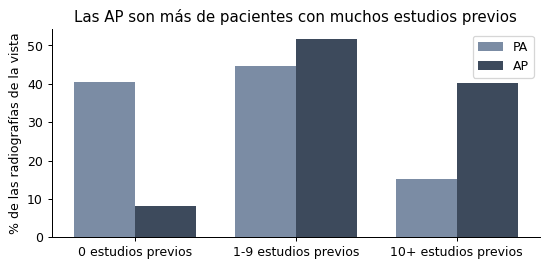

In [11]:
fig, ax = plt.subplots(figsize=(7, 3))
ancho = 0.38
for i, vista in enumerate(('PA', 'AP')):
    sub = [r for r in filas if r['View Position'] == vista]
    partes = Counter(follow_up_bin(r['previos']) for r in sub)
    x = np.arange(len(FOLLOW_UP_BINS)) + (i - 0.5) * ancho
    ax.bar(x, [100 * partes[b] / len(sub) for b in FOLLOW_UP_BINS], ancho, label=vista,
           color=COLOR[0] if vista == 'PA' else '#3d4a5c')
ax.set_xticks(range(len(FOLLOW_UP_BINS)), [f'{b} estudios previos' for b in FOLLOW_UP_BINS])
ax.set_ylabel('% de las radiografías de la vista')
ax.set_title('Las AP son más de pacientes con muchos estudios previos')
ax.legend()
plt.show()

### Cuánto se asocia la vista con el derrame y con los estudios previos

Los porcentajes de la tabla muestran diferencias, pero no dicen cuán fuertes son. Entre dos variables binarias la medida de asociación que corresponde es el **coeficiente Phi** (slides 04, p. 47): φ = √(χ²/n), donde χ² es el estadístico del test de independencia. Se lee en valor absoluto: menos de 0,1 es despreciable, de 0,1 a 0,3 débil, de 0,3 a 0,5 moderada y más de 0,5 fuerte (slides 04, pp. 36-37).

Para cada par se plantea un test χ² de independencia (slides 04, pp. 11-12 y 19), con el nivel de significancia fijado antes de mirar el resultado:

- **H0:** la vista y la otra variable son independientes. **H1:** están asociadas.
- **α = 0,05.** Si el p-valor es menor, se rechaza H0. Si no, no se rechaza, que no es lo mismo que aceptarla.

Se usan las 112.120 radiografías, PA y AP.

In [12]:
ALFA = 0.05


def chi_cuadrado(x, y):
    """Test χ² de independencia entre dos variables 0/1, sin corrección de Yates, y coeficiente Phi con su signo."""
    x, y = np.asarray(x), np.asarray(y)
    tabla = np.array([[np.sum((x == i) & (y == j)) for j in (0, 1)] for i in (0, 1)], dtype=float)
    esperada = tabla.sum(axis=1, keepdims=True) * tabla.sum(axis=0, keepdims=True) / tabla.sum()
    chi2 = float(((tabla - esperada) ** 2 / esperada).sum())
    p = math.erfc(math.sqrt(chi2 / 2))  # χ² con 1 grado de libertad
    phi = math.copysign(math.sqrt(chi2 / tabla.sum()), tabla[1, 1] * tabla[0, 0] - tabla[1, 0] * tabla[0, 1])
    return tabla, chi2, p, phi, esperada.min()


def miles(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')


def p_valor(p):
    if p < 1e-300:
        return '< 1e-300'
    return dec(p, 3) if p >= 0.001 else f'{p:.1e}'.replace('.', ',')


def decision(p):
    return 'se rechaza' if p < ALFA else 'no se rechaza'


def lectura_phi(phi):
    return 'despreciable' if abs(phi) < 0.1 else 'débil' if abs(phi) < 0.3 else 'moderada' if abs(phi) < 0.5 else 'fuerte'


es_ap = [int(r['View Position'] == 'AP') for r in filas]
pruebas = {'Effusion': [r['y'] for r in filas], '10 o más estudios previos': [int(r['previos'] >= 10) for r in filas]}
resultados = []
for nombre, valores in pruebas.items():
    tabla, chi2, p, phi, minima = chi_cuadrado(es_ap, valores)
    print(Tabla([f'Vista × {nombre}', 'No', 'Sí'], [['PA', n(tabla[0, 0]), n(tabla[0, 1])], ['AP', n(tabla[1, 0]), n(tabla[1, 1])]]))
    print(f'Menor frecuencia esperada: {n(minima)} (el χ² necesita al menos 5)\n')
    resultados.append([f'Vista AP × {nombre}', miles(chi2), p_valor(p), decision(p), dec(phi, 3), lectura_phi(phi)])
Tabla(['Variables (112.120 radiografías)', 'χ²', 'p-valor', 'H0 (α = 0,05)', 'φ', 'Lectura (slides 04, p. 37)'], resultados)

Vista × Effusion  No      Sí   
----------------  ------  -----
PA                60.721  6.589
AP                38.082  6.728
Menor frecuencia esperada: 5.322 (el χ² necesita al menos 5)



Vista × 10 o más estudios previos  No      Sí    
---------------------------------  ------  ------
PA                                 57.134  10.176
AP                                 26.768  18.042
Menor frecuencia esperada: 11.277 (el χ² necesita al menos 5)



Variables (112.120 radiografías),χ²,p-valor,"H0 (α = 0,05)",φ,"Lectura (slides 04, p. 37)"
Vista AP × Effusion,"701,8","1,2e-154",se rechaza,"0,079",despreciable
Vista AP × 10 o más estudios previos,"9.031,3",< 1e-300,se rechaza,"0,284",débil


**Decisión: usar solo radiografías PA.** El test rechaza la independencia en los dos casos, pero con 112.120 radiografías casi cualquier diferencia sale significativa: lo que importa es la magnitud.

- **Con *Effusion*, la asociación es despreciable** (φ = 0,079). No se excluyen las AP por tener más derrames.
- **Con tener 10 o más estudios previos, es débil y cerca de moderada** (φ = 0,284). Las AP son otra población: pacientes con mucho más seguimiento, probablemente internados. Además, en una placa AP el corazón se ve más grande y la imagen cambia. Si se mezclaran, el modelo podría aprender "AP = paciente con mucho seguimiento = derrame" en lugar del derrame.

Quedan afuera 44.810 radiografías AP. Una salvedad: el χ² supone observaciones independientes (slides 04, p. 21) y las radiografías de un mismo paciente no lo son, así que los p-valores salen más chicos de lo que deberían. El valor de φ no depende de eso.

## 4. Qué hallazgo clasificar

El profesor pidió el **mismo porcentaje de positivos en train y en test (40%)**; la consigna escrita no fija ninguno. Lo que limita es cuántos positivos hay en cada lista, y que train y test se parezcan. La tabla usa solo PA.

In [13]:
pa = [r for r in filas if r['View Position'] == 'PA']
listas = {nombre: [r for r in pa if r['lista'] == nombre] for nombre in ('train_val', 'test')}


def positivas(lista, hallazgo):
    return sum(hallazgo in r['hallazgos'] for r in lista)


candidatos = sorted({h for r in pa for h in r['hallazgos']} - {'No Finding'}, key=lambda h: -positivas(pa, h))
Tabla(['Hallazgo (solo PA)', 'Positivas', '% en train_val', '% en test oficial', 'Test más grande posible con 40%'],
      [[h, n(positivas(pa, h)), pct(positivas(listas['train_val'], h), len(listas['train_val'])),
        pct(positivas(listas['test'], h), len(listas['test'])), n(positivas(listas['test'], h) / 0.4)]
       for h in candidatos])

Hallazgo (solo PA),Positivas,% en train_val,% en test oficial,Test más grande posible con 40%
Infiltration,9.353,"13,7%","15,1%",4.180
Effusion,6.589,"8,6%","15,8%",4.390
Atelectasis,5.728,"7,8%","12,3%",3.402
Nodule,4.177,"5,9%","7,9%",2.182
Mass,3.567,"4,7%","8,5%",2.352
Pneumothorax,3.407,"3,3%","14,0%",3.877
Pleural_Thickening,2.418,"3,1%","6,2%",1.715
Cardiomegaly,1.563,"2,0%","3,8%",1.067
Consolidation,1.521,"2,0%","3,5%",975
Emphysema,1.499,"1,6%","5,6%",1.562


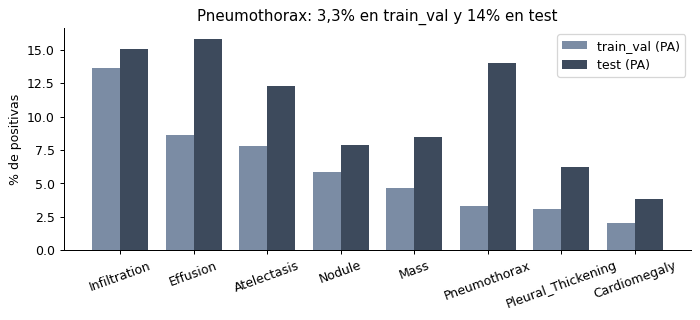

In [14]:
principales = candidatos[:8]
fig, ax = plt.subplots(figsize=(9, 3.2))
ancho = 0.38
for i, nombre in enumerate(('train_val', 'test')):
    lista = listas[nombre]
    x = np.arange(len(principales)) + (i - 0.5) * ancho
    ax.bar(x, [100 * positivas(lista, h) / len(lista) for h in principales], ancho,
           label=f'{nombre} (PA)', color=COLOR[0] if nombre == 'train_val' else '#3d4a5c')
ax.set_xticks(range(len(principales)), principales, rotation=20)
ax.set_ylabel('% de positivas')
ax.set_title('Pneumothorax: 3,3% en train_val y 14% en test')
ax.legend()
plt.show()

**Decisión: *Effusion*.**

- **El primer intento fue *Pneumothorax*** ([`docs/SPLITS_NIH_PNEUMOTHORAX.md`](../docs/SPLITS_NIH_PNEUMOTHORAX.md)), con las dos primeras carpetas de imágenes: daba 3,6% de positivas en train y 13,9% en test. Con el dataset completo el patrón es el mismo: tiene cuatro veces más positivas en el test oficial que en train_val. Además, en muchas de esas radiografías ya se ve el tubo de drenaje, un atajo obvio para el modelo.
- ***Effusion* tiene 6.589 positivas PA,** suficientes para un test oficial de 4.390 imágenes con 40% de positivas, y la diferencia entre train_val y test es menor.
- ***Infiltration* tiene más positivas,** pero es una etiqueta poco específica: describe opacidades de muchas causas. El derrame tiene un signo visual concreto, el borramiento de los ángulos entre las costillas y el diafragma.

## 5. Las negativas

Con 40% de positivas hay que elegir negativas. Hay dos preguntas: qué tipo de negativas, y cuántas por paciente.

In [15]:
negativas = [r for r in pa if not r['y']]
sin_hallazgos = sum(r['Finding Labels'] == 'No Finding' for r in negativas)
print(f'Negativas PA: {n(len(negativas))}. Sin hallazgos: {pct(sin_hallazgos, len(negativas))}; '
      f'con otros hallazgos: {pct(len(negativas) - sin_hallazgos, len(negativas))}')
negativas_train_val = [r for r in negativas if r['lista'] == 'train_val']
sin_hallazgos_train_val = sum(r['Finding Labels'] == 'No Finding' for r in negativas_train_val)
print(f'Solo con train_val_list.txt: {n(len(negativas_train_val))} negativas PA, '
      f'{pct(sin_hallazgos_train_val, len(negativas_train_val))} sin hallazgos')

neg_por_paciente = np.array(list(Counter(r['Patient ID'] for r in negativas).values()))
muchas = neg_por_paciente > 3
print(f'Pacientes con más de 3 negativas: {pct(muchas.sum(), len(neg_por_paciente))} de los pacientes, '
      f'pero aportan {pct(neg_por_paciente[muchas].sum(), len(negativas))} de las negativas')
print(f'Con un máximo de 3 por paciente quedan {n(np.minimum(neg_por_paciente, 3).sum())} negativas para elegir; '
      f'con 40% de positivas hacen falta {n(round(positivas(pa, TARGET) * 1.5))}')

Negativas PA: 60.721. Sin hallazgos: 64,7%; con otros hallazgos: 35,3%
Solo con train_val_list.txt: 51.381 negativas PA, 67,1% sin hallazgos
Pacientes con más de 3 negativas: 14,0% de los pacientes, pero aportan 47,0% de las negativas
Con un máximo de 3 por paciente quedan 43.979 negativas para elegir; con 40% de positivas hacen falta 9.884


**Decisiones:**

- **65% de negativas sin hallazgos y 35% con otros hallazgos**, la misma mezcla que tienen las negativas PA de NIH (64,7%). Así el modelo también aprende a distinguir el derrame de otras patologías, no solo de radiografías sanas. Una aclaración: el 65% se fijó mirando todas las PA, incluida la lista de test. En clase los parámetros se calculan solo con train (slides 06, pp. 30-31); con `train_val_list.txt` sola, la proporción es 67,1%. La diferencia es chica y no cambia la preparación ya hecha, pero queda anotada.
- **Como máximo 3 negativas por paciente.** Una pequeña parte de los pacientes aporta una porción grande de las negativas; sin límite, unos pocos pacientes con decenas de estudios dominarían el conjunto. Aun con el límite sobran negativas para elegir.
- **Se usan todas las positivas** y las negativas se eligen al azar con semilla 42.

## 6. Los conjuntos preparados

`rx-preparar --config configs/nih.json` aplica las decisiones anteriores. Además abre cada imagen para detectar archivos ilegibles y duplicados por hash de píxeles, separa por paciente (test = lista oficial; validación = 15% de los pacientes de train_val) y transforma las imágenes. Esta sección comprueba el resultado contra el CSV original.

In [16]:
requiere(PREPARADOS / 'report.json', 'Generarlo con: rx-preparar --config configs/nih.json')
reporte = json.loads((PREPARADOS / 'report.json').read_text())
motivos = {'excluded_view': 'Vista AP', 'duplicate_image': 'Copia exacta del mismo paciente (se conserva una)',
           'duplicate_across_patients': 'Imagen idéntica en pacientes distintos (se excluyen todas)'}
print(f"Filas del CSV: {n(reporte['source_rows'])}; aceptadas: {n(reporte['accepted_images'])}")
Tabla(['Motivo de exclusión', 'Radiografías'], [[motivos.get(k, k), n(v)] for k, v in reporte['exclusion_reasons'].items()])

Filas del CSV: 112.120; aceptadas: 67.298


Motivo de exclusión,Radiografías
Vista AP,44.810
Copia exacta del mismo paciente (se conserva una),3
Imagen idéntica en pacientes distintos (se excluyen todas),9


In [17]:
conjuntos = {}
for nombre in ('train', 'val', 'test'):
    with open(PREPARADOS / f'{nombre}.csv', newline='', encoding='utf-8') as stream:
        filas_conjunto = sorted(csv.DictReader(stream), key=lambda r: int(r['array_index']))
    y = np.load(PREPARADOS / f'y_{nombre}.npy')
    assert [int(r['target']) for r in filas_conjunto] == y.tolist(), f'{nombre}: el CSV no coincide con y'
    for r in filas_conjunto:
        r['meta'] = por_nombre[Path(r['image_path']).name]
    conjuntos[nombre] = filas_conjunto


def resumen(nombre):
    rs = conjuntos[nombre]
    pos = [r for r in rs if r['target'] == '1']
    neg = [r for r in rs if r['target'] == '0']
    maximo = max(Counter(r['patient_id'] for r in neg).values())
    return [nombre, n(len(rs)), n(len({r['patient_id'] for r in rs})), f'{n(len(pos))} ({pct(len(pos), len(rs))})',
            pct(sum(r['target_original'] == 'No Finding' for r in neg), len(neg)), maximo]


Tabla(['Conjunto', 'Radiografías', 'Pacientes', 'Con Effusion', 'Negativas sin hallazgos', 'Máx. negativas por paciente'],
      [resumen(nombre) for nombre in conjuntos])

Conjunto,Radiografías,Pacientes,Con Effusion,Negativas sin hallazgos,Máx. negativas por paciente
train,10.270,6.707,"4.108 (40,0%)","65,0%",3
val,1.813,1.181,"725 (40,0%)","65,0%",3
test,4.390,1.686,"1.756 (40,0%)","65,0%",3


In [18]:
nombres = {k: {Path(r['image_path']).name for r in v} for k, v in conjuntos.items()}
pacientes_de = {k: {r['patient_id'] for r in v} for k, v in conjuntos.items()}
hashes = {k: {r['pixel_hash'] for r in v} for k, v in conjuntos.items()}
pares = [('train', 'val'), ('train', 'test'), ('val', 'test')]
todas = [r for v in conjuntos.values() for r in v]
chequeos = {
    'Ningún paciente en dos conjuntos': all(not pacientes_de[a] & pacientes_de[b] for a, b in pares),
    'Ninguna imagen idéntica (hash de píxeles) en dos conjuntos': all(not hashes[a] & hashes[b] for a, b in pares),
    'Test = solo imágenes de test_list.txt': nombres['test'] <= test_oficial,
    'Train y val = solo imágenes de train_val_list.txt': not (nombres['train'] | nombres['val']) & test_oficial,
    'Todas son PA': all(r['meta']['View Position'] == 'PA' for r in todas),
    'Cada etiqueta coincide con el CSV original': all(int(r['target']) == r['meta']['y'] for r in todas),
    'Están todas las Effusion PA': sum(r['target'] == '1' for r in todas) == positivas(pa, TARGET),
    'Todas las imágenes miden 1024 × 1024': all((r['width'], r['height']) == ('1024', '1024') for r in todas),
}
for texto, ok in chequeos.items():
    print('OK   ' if ok else 'FALLA', texto)
assert all(chequeos.values())
print('Modo de las PNG:', dict(Counter(r['mode'] for r in todas)),
      '(las RGBA son opacas y se pasan a grises igual que las demás)')

OK    Ningún paciente en dos conjuntos
OK    Ninguna imagen idéntica (hash de píxeles) en dos conjuntos
OK    Test = solo imágenes de test_list.txt
OK    Train y val = solo imágenes de train_val_list.txt
OK    Todas son PA
OK    Cada etiqueta coincide con el CSV original
OK    Están todas las Effusion PA
OK    Todas las imágenes miden 1024 × 1024
Modo de las PNG: {'L': 16408, 'RGBA': 65} (las RGBA son opacas y se pasan a grises igual que las demás)


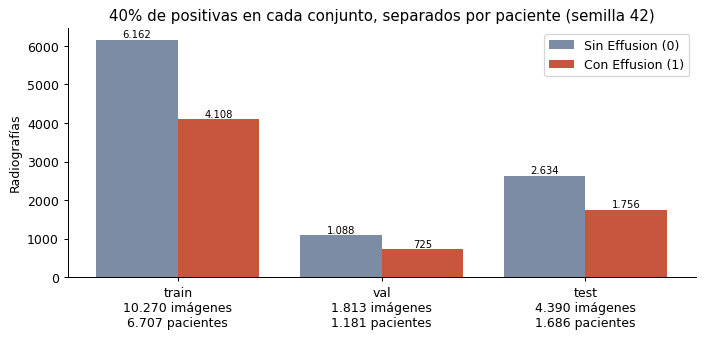

In [19]:
fig, ax = plt.subplots(figsize=(9, 3.6))
ancho = 0.4
for clase, desplazamiento in ((0, -0.5), (1, 0.5)):
    valores = [sum(r['target'] == str(clase) for r in conjuntos[k]) for k in conjuntos]
    barras = ax.bar(np.arange(3) + desplazamiento * ancho, valores, ancho, color=COLOR[clase],
                    label='Con Effusion (1)' if clase else 'Sin Effusion (0)')
    ax.bar_label(barras, [n(v) for v in valores], fontsize=8)
ax.set_xticks(range(3), [f'{k}\n{n(len(v))} imágenes\n{n(len(pacientes_de[k]))} pacientes' for k, v in conjuntos.items()])
ax.set_ylabel('Radiografías')
ax.set_title('40% de positivas en cada conjunto, separados por paciente (semilla 42)')
ax.legend()
plt.show()

**Decisiones:**

- **Test = la lista oficial de NIH.** No lo elegimos nosotros, y es el que usa la literatura.
- **40% de positivas también en validación y test,** como pidió el profesor. El material de clase balancea solo train; acá en validación y test solo se eligen imágenes, sin repetir ni generar ninguna. La consecuencia es que precisión y F1 salen más altos que con la proporción real (9,8% en PA).
- **Duplicados:** si la misma imagen aparece en dos pacientes distintos no se sabe cuál es el correcto, y podría quedar en train y en test a la vez. Se excluyen las 9.

## 7. Train: edad, sexo y estudios previos

Desde acá se mira **solo train**: es el conjunto con el que se toman las decisiones de modelado.

In [20]:
train = conjuntos['train']
por_clase = {c: [r for r in train if r['target'] == str(c)] for c in (1, 0)}
Tabla(['Train', 'Radiografías', 'Edad media', '% hombres', 'Estudios previos (mediana)', 'Con 10 o más estudios previos'],
      [['Con Effusion' if c else 'Sin Effusion', n(len(rs)), dec(np.mean([r['meta']['edad'] for r in rs])),
        pct(sum(r['meta']['Patient Sex'] == 'M' for r in rs), len(rs), 0),
        f"{np.median([r['meta']['previos'] for r in rs]):.0f}",
        pct(sum(r['meta']['previos'] >= 10 for r in rs), len(rs))] for c, rs in por_clase.items()])

Train,Radiografías,Edad media,% hombres,Estudios previos (mediana),Con 10 o más estudios previos
Con Effusion,4.108,"51,3",55%,4,"22,2%"
Sin Effusion,6.162,"46,5",54%,1,"8,6%"


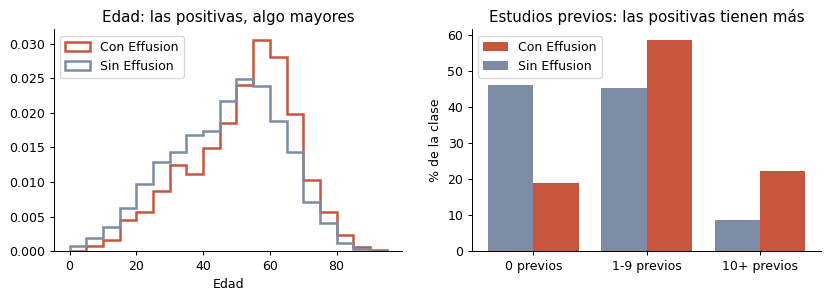

Solo con el número de estudios previos, sin mirar la imagen, ya se separan las clases de train con AUC 0,684


In [21]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(11, 3.2))
for c, rs in por_clase.items():
    etiqueta = 'Con Effusion' if c else 'Sin Effusion'
    izq.hist([r['meta']['edad'] for r in rs], bins=np.arange(0, 100, 5), density=True, histtype='step',
             linewidth=2, color=COLOR[c], label=etiqueta)
    partes = Counter(follow_up_bin(r['meta']['previos']) for r in rs)
    x = np.arange(len(FOLLOW_UP_BINS)) + (0.2 if c else -0.2)
    der.bar(x, [100 * partes[b] / len(rs) for b in FOLLOW_UP_BINS], 0.4, color=COLOR[c], label=etiqueta)
izq.set_xlabel('Edad')
izq.set_title('Edad: las positivas, algo mayores')
izq.legend()
der.set_xticks(range(len(FOLLOW_UP_BINS)), [f'{b} previos' for b in FOLLOW_UP_BINS])
der.set_ylabel('% de la clase')
der.set_title('Estudios previos: las positivas tienen más')
der.legend()
plt.show()

auc_previos = roc_auc([int(r['target']) for r in train], [r['meta']['previos'] for r in train])
print(f'Solo con el número de estudios previos, sin mirar la imagen, ya se separan las clases de train con AUC {dec(auc_previos, 3)}')

### Medidas de asociación con el target

Las diferencias de la tabla se miden con la medida que corresponde a cada par de tipos de variable (slides 04, p. 47):

- **Edad y estudios previos** (numéricas) contra *Effusion* (binaria): **correlación punto biserial**, que es la de Pearson cuando una de las dos variables vale 0 o 1. Se lee en valor absoluto: menos de 0,2 es débil, de 0,2 a 0,4 moderada y más de 0,4 fuerte (slides 04, pp. 38-39).
- **Sexo** (binaria) contra *Effusion*: **coeficiente Phi**, con la escala de la sección 3.
- Como los estudios previos son muy asimétricos (sección 1), se agrega **Spearman**, que trabaja con rangos y es robusta a la asimetría y a los outliers (slides 03, p. 50).

En cada caso, **H0:** no hay asociación (correlación 0, o independencia en el χ²); **H1:** sí la hay; **α = 0,05**, fijado antes. Para las correlaciones, el p-valor sale de t = r·√((n − 2)/(1 − r²)), que con n = 10.270 se comporta como una normal.

**Un supuesto que no se cumple del todo:** varias radiografías de train son del mismo paciente, así que las observaciones no son independientes (slides 04, p. 21). Los p-valores salen optimistas; las magnitudes de las medidas no cambian.

In [22]:
def correlacion(x, y):
    """Correlación de Pearson y su p-valor bilateral, con la aproximación normal de t (n grande)."""
    r = float(np.corrcoef(x, y)[0, 1])
    t = r * math.sqrt((len(x) - 2) / (1 - r ** 2))
    return r, math.erfc(abs(t) / math.sqrt(2))


def rangos(valores):
    """Rangos con los empates promediados, igual que en roc_auc."""
    _, inversa, cuentas = np.unique(valores, return_inverse=True, return_counts=True)
    return (np.cumsum(cuentas) - (cuentas - 1) / 2)[inversa]


def lectura_biserial(r):
    return 'débil' if abs(r) < 0.2 else 'moderada' if abs(r) < 0.4 else 'fuerte'


y_tr = np.array([int(r['target']) for r in train])
edad_tr = np.array([r['meta']['edad'] for r in train])
previos_tr = np.array([r['meta']['previos'] for r in train])
hombre_tr = np.array([int(r['meta']['Patient Sex'] == 'M') for r in train])

r_edad, p_edad = correlacion(edad_tr, y_tr)
r_previos, p_previos = correlacion(previos_tr, y_tr)
rho_previos, p_rho = correlacion(rangos(previos_tr), rangos(y_tr))
_, chi2_sexo, p_sexo, phi_sexo, _ = chi_cuadrado(hombre_tr, y_tr)

q1, mediana, q3 = np.percentile(previos_tr[y_tr == 1], [25, 50, 75])
print(f'Estudios previos de las positivas de train: Q1 {q1:.0f}, mediana {mediana:.0f}, Q3 {q3:.0f}')
Tabla(['Variable × Effusion (train)', 'Medida', 'Valor', 'p-valor', 'H0 (α = 0,05)', 'Lectura'],
      [['Edad', 'Punto biserial', dec(r_edad, 3), p_valor(p_edad), decision(p_edad), lectura_biserial(r_edad)],
       ['Sexo (hombre = 1)', f'Phi (χ² = {dec(chi2_sexo, 2)})', dec(phi_sexo, 3), p_valor(p_sexo), decision(p_sexo),
        lectura_phi(phi_sexo)],
       ['Estudios previos', 'Punto biserial', dec(r_previos, 3), p_valor(p_previos), decision(p_previos),
        lectura_biserial(r_previos)],
       ['Estudios previos', 'Spearman', dec(rho_previos, 3), p_valor(p_rho), decision(p_rho),
        'confirma la anterior, sin depender de la asimetría'],
       ['Estudios previos', 'AUC (medida extra)', dec(auc_previos, 3), '-', '-', '0,5 sería no separar nada']])

Estudios previos de las positivas de train: Q1 1, mediana 4, Q3 9


Variable × Effusion (train),Medida,Valor,p-valor,"H0 (α = 0,05)",Lectura
Edad,Punto biserial,"0,145","4,8e-50",se rechaza,débil
Sexo (hombre = 1),"Phi (χ² = 0,28)","0,005","0,599",no se rechaza,despreciable
Estudios previos,Punto biserial,"0,245","6,1e-145",se rechaza,moderada
Estudios previos,Spearman,"0,321","7,4e-258",se rechaza,"confirma la anterior, sin depender de la asimetría"
Estudios previos,AUC (medida extra),"0,684",-,-,"0,5 sería no separar nada"


**Decisiones:**

- **No se balancea por edad ni por sexo.** Las positivas son en promedio unos 5 años mayores (51 contra 47), pero la asociación de la edad con *Effusion* es **débil** (punto biserial 0,145). El porcentaje de hombres es casi igual (55% y 54%) y la asociación del sexo es **despreciable** (φ = 0,005): ni siquiera se rechaza la independencia (p = 0,60), lo que no prueba que sean independientes, pero muestra que no hay evidencia suficiente de asociación.
- **Los estudios previos quedan como riesgo a vigilar.** Su asociación con *Effusion* es **moderada** (punto biserial 0,245; Spearman 0,321), la más alta de las tres. Las positivas son más de pacientes seguidos durante mucho tiempo, que suelen tener cables, catéteres o vías. Solo con ese número, sin mirar la imagen, las clases de train ya se separan con AUC 0,68, una medida extra a las de clase que dice lo mismo: el modelo podría aprender "paciente internado" además de "derrame". NIH no marca los dispositivos, así que no se pueden filtrar: en una muestra revisada a ojo se vieron en ~30% de las positivas y ~13% de las negativas ([`docs/SPLITS_NIH_EFFUSION.md`](../docs/SPLITS_NIH_EFFUSION.md)). Se mide después, en el análisis de errores.
- **Estudios previos agrupados en 0, 1-9 y 10 o más** (`FOLLOW_UP_BINS`). Son cortes fijos por dominio, una de las formas de discretizar que se ven en clase (slides 06, pp. 13-18): 0 es el primer estudio del paciente y 10 o más marca un seguimiento largo, justo por encima del Q3 de las positivas de train (9). Se prefirieron a los cuantiles, que la clase recomienda para datos asimétricos, porque son fáciles de interpretar y son los mismos en todos los grupos: así se pueden comparar las vistas (sección 3) y train con el test oficial (sección 9).

## 8. Train: las imágenes

La preparación pasa cada imagen a escala de grises, la lleva a 224×224 sin deformarla (bordes negros si no es cuadrada) y deja los valores en [0, 1] dividiendo por 255. Media y desvío se calculan **solo con train** y se aplican igual a validación, test e imágenes nuevas.

X_train: (10270, 224, 224), float32; y_train: (10270,)
Media y desvío de train, guardados en preprocessing.json: 0,508 y 0,265


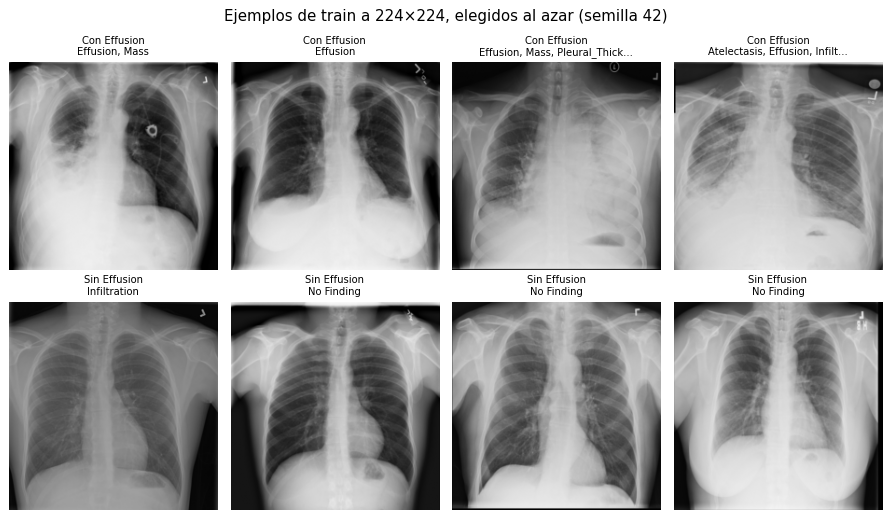

In [23]:
X_train = np.load(PREPARADOS / 'X_train.npy', mmap_mode='r')
y_train = np.load(PREPARADOS / 'y_train.npy')
preprocesamiento = json.loads((PREPARADOS / 'preprocessing.json').read_text())
print(f'X_train: {X_train.shape}, {X_train.dtype}; y_train: {y_train.shape}')
print(f"Media y desvío de train, guardados en preprocessing.json: {dec(preprocesamiento['train_mean'], 3)} y "
      f"{dec(preprocesamiento['train_std'], 3)}")

rng = np.random.default_rng(SEED)
fig, ejes = plt.subplots(2, 4, figsize=(10, 6))
for fila, clase in zip(ejes, (1, 0)):
    for ax, i in zip(fila, rng.choice(np.flatnonzero(y_train == clase), 4, replace=False)):
        ax.imshow(X_train[i], cmap='gray', vmin=0, vmax=1)
        etiquetas = train[i]['meta']['Finding Labels'].replace('|', ', ')
        etiquetas = etiquetas if len(etiquetas) <= 32 else etiquetas[:29] + '...'
        ax.set_title(f"{'Con' if clase else 'Sin'} Effusion\n{etiquetas}", fontsize=8)
        ax.axis('off')
fig.suptitle('Ejemplos de train a 224×224, elegidos al azar (semilla 42)')
plt.tight_layout()
plt.show()

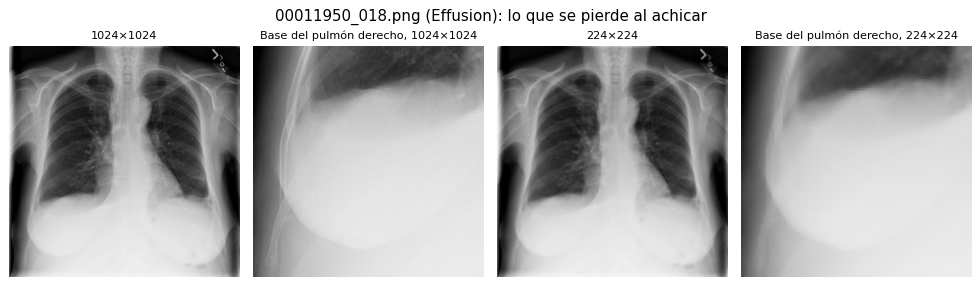

In [24]:
# Una positiva de train al azar, en su tamaño publicado y como la ve el modelo.
i = int(np.random.default_rng(SEED).choice(np.flatnonzero(y_train == 1)))
nombre = Path(train[i]['image_path']).name
ruta = Path(train[i]['image_path'])
if not ruta.exists():
    ruta = next(NIH.rglob(nombre))
original, _ = read_image(ruta)
chica = transform(ruta, 224)

fig, ejes = plt.subplots(1, 4, figsize=(11, 3.2))
recortes = [(original, original[600:980, 40:420], 1024), (chica, chica[131:214, 9:92], 224)]
for (completa, recorte, lado), (ax_completa, ax_recorte) in zip(recortes, (ejes[:2], ejes[2:])):
    ax_completa.imshow(completa, cmap='gray', vmin=0, vmax=1)
    ax_completa.set_title(f'{lado}×{lado}', fontsize=9)
    ax_recorte.imshow(recorte, cmap='gray', vmin=0, vmax=1)
    ax_recorte.set_title(f'Base del pulmón derecho, {lado}×{lado}', fontsize=9)
for ax in ejes:
    ax.axis('off')
fig.suptitle(f'{nombre} ({train[i]["meta"]["Finding Labels"]}): lo que se pierde al achicar')
plt.tight_layout()
plt.show()

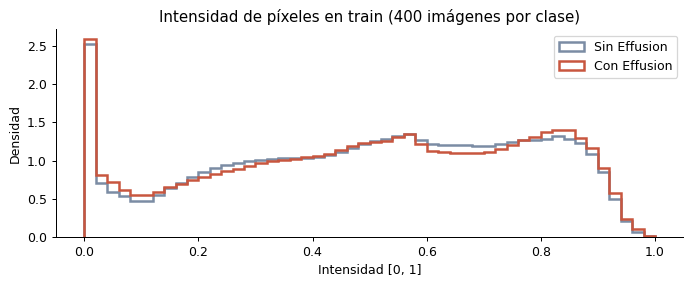

In [25]:
# Intensidades de 400 imágenes por clase.
rng = np.random.default_rng(SEED)
fig, ax = plt.subplots(figsize=(9, 3))
for clase in (0, 1):
    indices = np.sort(rng.choice(np.flatnonzero(y_train == clase), 400, replace=False))
    ax.hist(np.asarray(X_train[indices]).ravel(), bins=50, range=(0, 1), density=True, histtype='step',
            linewidth=2, color=COLOR[clase], label='Con Effusion' if clase else 'Sin Effusion')
ax.set_xlabel('Intensidad [0, 1]')
ax.set_ylabel('Densidad')
ax.set_title('Intensidad de píxeles en train (400 imágenes por clase)')
ax.legend()
plt.show()

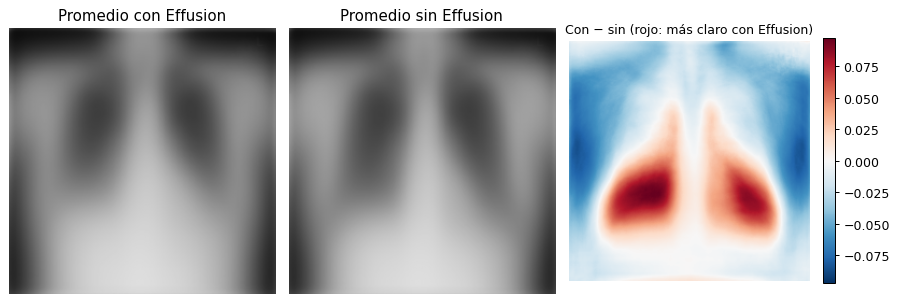

In [26]:
# Imagen promedio de cada clase, y brillo (media) y contraste (desvío) de cada imagen, recorriendo train por bloques.
suma = {0: np.zeros((224, 224)), 1: np.zeros((224, 224))}
brillos = np.empty(len(X_train))
desvios = np.empty(len(X_train))
for inicio in range(0, len(X_train), 1000):
    bloque = np.asarray(X_train[inicio:inicio + 1000], dtype=np.float64)
    for clase in (0, 1):
        suma[clase] += bloque[y_train[inicio:inicio + 1000] == clase].sum(axis=0)
    brillos[inicio:inicio + 1000] = bloque.reshape(len(bloque), -1).mean(axis=1)
    desvios[inicio:inicio + 1000] = bloque.reshape(len(bloque), -1).std(axis=1)
promedio = {clase: suma[clase] / (y_train == clase).sum() for clase in (0, 1)}

fig, ejes = plt.subplots(1, 3, figsize=(10, 3.6))
ejes[0].imshow(promedio[1], cmap='gray', vmin=0, vmax=1)
ejes[0].set_title('Promedio con Effusion')
ejes[1].imshow(promedio[0], cmap='gray', vmin=0, vmax=1)
ejes[1].set_title('Promedio sin Effusion')
diferencia = promedio[1] - promedio[0]
limite = np.abs(diferencia).max()
imagen = ejes[2].imshow(diferencia, cmap='RdBu_r', vmin=-limite, vmax=limite)
ejes[2].set_title('Con − sin (rojo: más claro con Effusion)', fontsize=10)
fig.colorbar(imagen, ax=ejes[2], fraction=0.046)
for ax in ejes:
    ax.axis('off')
plt.tight_layout()
plt.show()

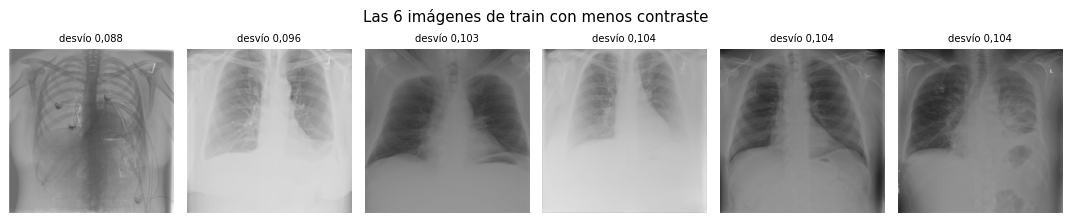

Desvío de las imágenes de train: mediana 0,257, mínimo 0,088


In [27]:
menor_contraste = np.argsort(desvios)[:6]
fig, ejes = plt.subplots(1, 6, figsize=(12, 2.5))
for ax, i in zip(ejes, menor_contraste):
    ax.imshow(X_train[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f'desvío {dec(desvios[i], 3)}', fontsize=8)
    ax.axis('off')
fig.suptitle('Las 6 imágenes de train con menos contraste')
plt.tight_layout()
plt.show()
print(f'Desvío de las imágenes de train: mediana {dec(np.median(desvios), 3)}, mínimo {dec(desvios.min(), 3)}')

### Outliers de brillo y contraste

Cada imagen de train se resume en dos números: el **brillo** (la media de sus píxeles) y el **contraste** (su desvío). Sobre esos 10.270 valores se buscan outliers con las dos reglas de clase (slides 04, pp. 50-51):

- **IQR:** fuera de [Q1 − 1,5·IQR, Q3 + 1,5·IQR].
- **Media ± 3 desvíos,** con el desvío muestral (n − 1).

Que una imagen quede marcada no alcanza para sacarla: hay que mirar los casos y decidir si son errores o valores legítimos (slides 05, p. 24), como hace el ejemplo del SMN visto en clase con las estaciones antárticas.

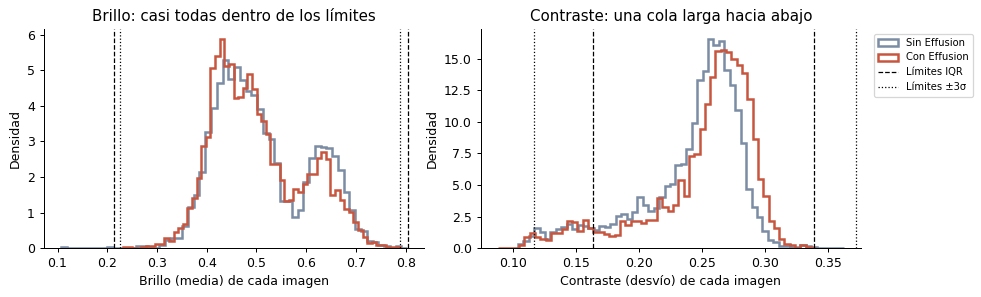

Medida,Regla,Límites,Por debajo,Por encima,Marcadas con Effusion (% de la clase),Marcadas sin Effusion (% de la clase)
Brillo (media),IQR,"0,213 a 0,805",6,0,"0 (0,0%)","6 (0,1%)"
Brillo (media),±3σ,"0,226 a 0,789",6,2,"0 (0,0%)","8 (0,1%)"
Contraste (desvío),IQR,"0,163 a 0,339",788,7,"308 (7,5%)","487 (7,9%)"
Contraste (desvío),±3σ,"0,117 a 0,372",94,0,"43 (1,0%)","51 (0,8%)"


In [28]:
def limites(valores):
    q1, q3 = np.percentile(valores, [25, 75])
    media, desvio = valores.mean(), valores.std(ddof=1)
    return {'IQR': (q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)), '±3σ': (media - 3 * desvio, media + 3 * desvio)}


medidas = {'Brillo (media)': brillos, 'Contraste (desvío)': desvios}
marcadas = {}
filas_outliers = []
for medida, valores in medidas.items():
    for regla, (inferior, superior) in limites(valores).items():
        bajo, alto = valores < inferior, valores > superior
        marcadas[medida, regla] = (bajo, alto)
        fuera = bajo | alto
        por_clase_fuera = [f'{n(fuera[y_train == c].sum())} ({pct(fuera[y_train == c].sum(), (y_train == c).sum())})'
                           for c in (1, 0)]
        filas_outliers.append([medida, regla, f'{dec(inferior, 3)} a {dec(superior, 3)}', n(bajo.sum()), n(alto.sum()),
                               *por_clase_fuera])

fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, (medida, valores) in zip(ejes, medidas.items()):
    for clase in (0, 1):
        ax.hist(valores[y_train == clase], bins=60, density=True, histtype='step', linewidth=2, color=COLOR[clase],
                label='Con Effusion' if clase else 'Sin Effusion')
    for regla, estilo in (('IQR', '--'), ('±3σ', ':')):
        for j, limite in enumerate(limites(valores)[regla]):
            ax.axvline(limite, color='black', linestyle=estilo, linewidth=1, label=f'Límites {regla}' if j == 0 else None)
    ax.set_xlabel(f'{medida} de cada imagen')
    ax.set_ylabel('Densidad')
ejes[0].set_title('Brillo: casi todas dentro de los límites')
ejes[1].set_title('Contraste: una cola larga hacia abajo')
ejes[1].legend(fontsize=8, loc='upper left', bbox_to_anchor=(1.02, 1))
plt.tight_layout()
plt.show()

Tabla(['Medida', 'Regla', 'Límites', 'Por debajo', 'Por encima', 'Marcadas con Effusion (% de la clase)',
       'Marcadas sin Effusion (% de la clase)'], filas_outliers)

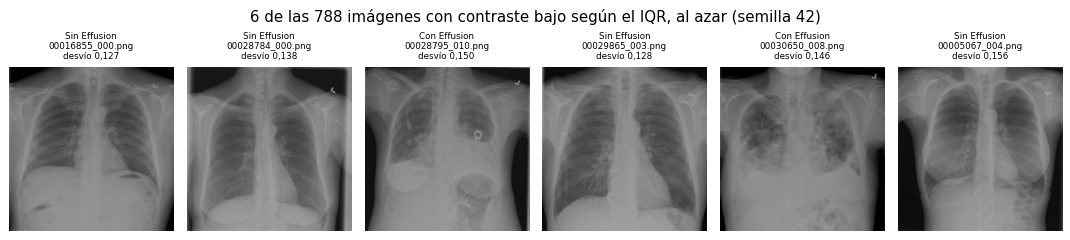

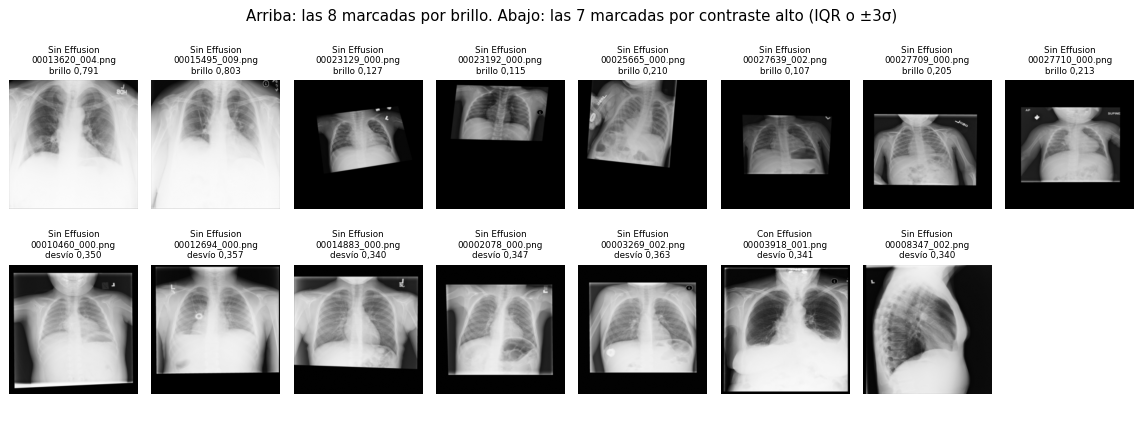

In [29]:
def mostrar(ax, i, texto):
    ax.imshow(X_train[i], cmap='gray', vmin=0, vmax=1)
    ax.set_title(f"{'Con' if y_train[i] else 'Sin'} Effusion\n{train[i]['meta']['Image Index']}\n{texto}", fontsize=7)


bajo_contraste = np.flatnonzero(marcadas['Contraste (desvío)', 'IQR'][0])
rng = np.random.default_rng(SEED)
fig, ejes = plt.subplots(1, 6, figsize=(12, 2.9))
for ax, i in zip(ejes, np.sort(rng.choice(bajo_contraste, 6, replace=False))):
    mostrar(ax, i, f'desvío {dec(desvios[i], 3)}')
    ax.axis('off')
fig.suptitle(f'6 de las {n(len(bajo_contraste))} imágenes con contraste bajo según el IQR, al azar (semilla 42)')
plt.tight_layout()
plt.show()

fuera_brillo = np.flatnonzero(np.logical_or.reduce([b | a for (m, _), (b, a) in marcadas.items() if m.startswith('Brillo')]))
contraste_alto = np.flatnonzero(np.logical_or.reduce([a for (m, _), (_, a) in marcadas.items() if m.startswith('Contraste')]))
columnas_fig = max(len(fuera_brillo), len(contraste_alto))
fig, ejes = plt.subplots(2, columnas_fig, figsize=(1.6 * columnas_fig, 4.9))
for fila, indices, valores, texto in ((ejes[0], fuera_brillo, brillos, 'brillo'), (ejes[1], contraste_alto, desvios, 'desvío')):
    for ax, i in zip(fila, indices):
        mostrar(ax, i, f'{texto} {dec(valores[i], 3)}')
    for ax in fila:
        ax.axis('off')
fig.suptitle(f'Arriba: las {len(fuera_brillo)} marcadas por brillo. Abajo: las {len(contraste_alto)} marcadas por contraste alto '
             '(IQR o ±3σ)')
plt.tight_layout()
plt.show()

**Decisiones:**

- **224×224 sin deformar,** el tamaño con el que se preentrenó DenseNet121. Las NIH son cuadradas, así que no llevan bordes; los bordes son para imágenes nuevas que no lo sean. El costo se ve en el recorte: a 224 un derrame chico en el ángulo costofrénico ocupa pocos píxeles. Por eso una resolución mayor está en el roadmap.
- **Escala fija /255, no por el máximo de cada imagen,** para que un mismo gris signifique lo mismo en todas.
- **El brillo solo no separa las clases:** los histogramas casi se superponen. El modelo tiene que aprender dónde está lo claro, no cuánto. La imagen promedio lo muestra: las positivas son más claras en la mitad inferior de los dos pulmones, donde se acumula el líquido.
- **No se filtra por calidad.** Casi todo lo que marcan las dos reglas es **contraste bajo**: 788 imágenes según el IQR y 94 según ±3σ. Por contraste quedan marcadas proporciones parecidas de las dos clases: 7,5% de las positivas y 7,9% de las negativas con el IQR, y 1,0% y 0,8% con ±3σ. Mirándolas, son placas lavadas o muy procesadas, pero se leen. La de menor contraste de todas parece invertida y tiene electrodos de ECG, y es un caso aislado. Las 7 de contraste alto son placas que no llenan el cuadro y tienen franjas negras alrededor (el negro ya viene en la PNG de NIH), y las de brillo atípico son placas chicas rodeadas de negro o muy sobreexpuestas. Como las estaciones antárticas del ejemplo del SMN, son valores raros pero legítimos, así que se conservan. Un filtro automático por brillo o contraste sacaría placas válidas.
- **Dos salvedades.** Las 8 imágenes de brillo atípico son todas negativas (0,1% de las negativas, ninguna positiva): son muy pocas para que el brillo sirva de atajo, pero la diferencia entre clases existe. Y entre las de contraste alto aparece una placa **lateral** etiquetada como PA en el CSV (`00008347_002.png`, negativa): es el único error que apareció. Es 1 de 10.270 imágenes; no se sacó para no rehacer los conjuntos, y queda anotada como límite.
- **Aumento de datos solo en train,** al entrenar: rotación ±7°, escala y desplazamiento ±5%. **Sin espejar,** porque el corazón está a la izquierda.

## 9. La población del test oficial (análisis posterior)

> Esta sección se agregó **después** de evaluar el modelo B en el test oficial, para entender por qué rindió peor que en validación. No cambia ninguno de los conjuntos de arriba: motivó el experimento del modelo C, que usó un test nuevo ([`docs/MODELO_C.md`](../docs/MODELO_C.md)).

In [30]:
def con_diez_o_mas(rs, clase):
    sub = [r for r in rs if r['y'] == clase]
    return pct(sum(r['previos'] >= 10 for r in sub), len(sub))


grupos = [('Lista train_val, todas las PA', listas['train_val']), ('Lista test, todas las PA', listas['test'])]
grupos += [(f'Conjunto {k} preparado', [r['meta'] for r in v]) for k, v in conjuntos.items()]
Tabla(['Grupo', 'Positivas con 10+ estudios previos', 'Negativas con 10+ estudios previos'],
      [[nombre, con_diez_o_mas(rs, 1), con_diez_o_mas(rs, 0)] for nombre, rs in grupos])

Grupo,Positivas con 10+ estudios previos,Negativas con 10+ estudios previos
"Lista train_val, todas las PA","21,8%","9,0%"
"Lista test, todas las PA","53,1%","38,3%"
Conjunto train preparado,"22,2%","8,6%"
Conjunto val preparado,"19,6%","9,0%"
Conjunto test preparado,"53,1%","24,8%"


El test oficial tiene muchos más pacientes con 10 o más estudios previos que train y validación, que salen los dos de la lista train_val. En esos pacientes el modelo B confundió muchas más negativas: su especificidad bajó a 35%. Validación, al ser un 15% al azar de train_val, no lo anticipó. El análisis completo está en [`docs/RESULTADOS_MODELOS.md`](../docs/RESULTADOS_MODELOS.md).

## 10. Resumen de decisiones

| Decisión | Por qué | Sección | Dónde está |
|---|---|---|---|
| Sin imputar ni eliminar filas | 0 faltantes en las 11 columnas del CSV y ningún valor imposible (edades de 0 a 95) | 1 | - |
| Estudios previos resumidos con mediana e IQR | Asimetría 4,2: la media no es representativa | 1 | - |
| Binaria: *Effusion* sola o con otros hallazgos | La mayoría de los derrames viene con otros hallazgos | 2 | `target` en `configs/nih.json` |
| *Effusion* en lugar de *Pneumothorax* | Pneumothorax: pocas positivas en train y 4 veces más en test, más el atajo del tubo de drenaje | 4 | `target` |
| Solo PA | Las AP son otra población: φ(AP, 10+ previos) = 0,28, débil cerca de moderada. Con *Effusion*, φ = 0,08: despreciable | 3 | `views` |
| Split por paciente; test = lista oficial | 84% de las radiografías es de pacientes con varios estudios | 1 y 6 | `ratios`, `test_list.txt` |
| 40% de positivas en los tres conjuntos | Pedido del profesor. Corrige el desbalance: entropía de 0,46 a 0,97 bits, Gini de 0,18 a 0,48. F1 y precisión quedan más altos que con la proporción real | 2, 4 y 6 | `selection.positive_fraction` |
| Negativas 65% sin hallazgos / 35% con otros | Es la mezcla real de las negativas PA (64,7%; 67,1% solo con train_val) | 5 | `selection.no_finding_share` |
| Máximo 3 negativas por paciente | Pocos pacientes concentran muchas negativas | 5 | `selection.max_negatives_per_patient` |
| Excluir duplicados idénticos | Evitan que la misma imagen quede en dos conjuntos | 6 | auditoría de `rx-preparar` |
| No balancear por edad ni sexo | Edad: punto biserial 0,15, débil. Sexo: φ = 0,005, despreciable | 7 | - |
| Estudios previos como riesgo de atajo, en 0 / 1-9 / 10+ | Punto biserial 0,25, moderada (Spearman 0,32). Cortes fijos por dominio; 10+ queda por encima del Q3 de las positivas (9) | 7 y 9 | `FOLLOW_UP_BINS` en `rx_torax.data.splits` |
| 224×224, /255, media y desvío de train | Tamaño de DenseNet121; sin información de validación ni test | 8 | `image_size`, `preprocessing.json` |
| Sin filtro de calidad | Los outliers de brillo y contraste (IQR y ±3σ) son placas legítimas; los de contraste, en proporción parecida en las dos clases | 8 | - |
| Aumento sin espejar | El corazón está a la izquierda | 8 | `augmentation` en `configs/modelo_*.json` |

**Límites que quedan:** las etiquetas tienen ruido porque salen de informes; los dispositivos no están anotados; todo es de un solo hospital; el test oficial tiene más pacientes con muchos estudios previos que train (sección 9); y en train quedó al menos una placa lateral etiquetada como PA (sección 8).